# CO₂ injection wells: fluid behaviour, shutdown and thermal loading

**Companion study for [NeqSim issue #4509](https://github.com/equinor/neqsim/issues/4509) · Version 1.0.0**

[Open in Google Colab](https://colab.research.google.com/github/EvenSol/NeqSim-Colab/blob/colab/co2-well-integrity-4509/notebooks/reservoir/co2_injection_well_integrity_paper_4509.ipynb)

Build a reproducible CO₂ injection study with current-source NeqSim. Follow the chain from
fluid properties to a flowing well, impurity partitioning, simplified shutdown and an
elastic thermal-loading screen. Every numerical result and plot is retained below.

**You will learn to:** compare cubic equations of state with a Span–Wagner reference;
construct a composable `ProcessSystem`; check pressure, temperature, phase and mass results;
and distinguish a fluid calculation from a well-integrity assessment.

**Paper:** Yongfeng Kang, Zhengchun Liu and Mihai Fleica (2025), *Ensuring Well Integrity in
Carbon Storage: Modeling CO2 Flow, Temperature and Pressure Behavior, and Stress Risks*,
ADIPEC, [SPE-229116-MS](https://doi.org/10.2118/229116-MS).
The issue supplies the research theme. The full paper and numerical case data were not
available for this study. All geometry, compositions and operating points below are
**synthetic teaching inputs**. This is an independent companion, not a numerical reproduction
of the paper or a validation against its proprietary software.

## 1. Runtime and provenance

Run all cells from a fresh Python 3.12 / Java 17+ runtime. The setup installs missing Python
packages, checks out an immutable commit that was on NeqSim `master` on 22 October 2026,
builds the shaded JAR and checks the Java class origin. The first Colab build can take several
minutes. Restart the runtime before changing the JAR. The optional `NEQSIM_SOURCE_ROOT` and
`NEQSIM_SOURCE_JAR` variables reuse a clean, matching local build; the commit, worktree,
JAR hash and class-origin checks still apply. The Colab network/build path is provided;
validation here used that local-build option.

In [1]:
import hashlib
import importlib.metadata
import importlib.util
import json
import os
from pathlib import Path
import subprocess
import sys
import zipfile

NEQSIM_SOURCE_REF = "cb94f1d10cbc12f5aa6452c095fe58c8ff44f3ae"
os.environ["NEQSIM_JVM_AUTOSTART"] = "0"
requirements = {
    "jpype": "JPype1==1.7.1",
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "CoolProp": "CoolProp==7.2.0",
}
missing = [
    requirement
    for module, requirement in requirements.items()
    if importlib.util.find_spec(module) is None
]
if missing:
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "--quiet", *missing],
        check=True,
    )

source_root = Path(os.environ.get("NEQSIM_SOURCE_ROOT", "neqsim-source")).resolve()
if not source_root.exists():
    subprocess.run(
        ["git", "clone", "--filter=blob:none", "--no-checkout",
         "https://github.com/equinor/neqsim.git", str(source_root)],
        check=True,
        capture_output=True,
        text=True,
    )
    subprocess.run(
        ["git", "checkout", NEQSIM_SOURCE_REF],
        cwd=source_root,
        check=True,
        capture_output=True,
        text=True,
    )
source_sha = subprocess.check_output(
    ["git", "rev-parse", "HEAD"], cwd=source_root, text=True
).strip()
assert source_sha == NEQSIM_SOURCE_REF, "Source revision differs from the pinned master commit"
assert not subprocess.check_output(
    ["git", "status", "--porcelain", "--untracked-files=no"],
    cwd=source_root,
    text=True,
).strip(), "Tracked source changes would invalidate provenance"

source_jar = Path(
    os.environ.get("NEQSIM_SOURCE_JAR", source_root / "target" / "neqsim-3.26.0.jar")
).resolve()
if not source_jar.is_file():
    build = subprocess.run(
        ["bash", "mvnw", "-q", "-DskipTests", "-Dmaven.test.skip=true",
         "-Dcheckstyle.skip", "-Dspotless.skip=true", "-Dmaven.javadoc.skip=true", "package"],
        cwd=source_root,
        capture_output=True,
        text=True,
    )
    if build.returncode:
        print(build.stdout[-8000:])
        print(build.stderr[-8000:])
        build.check_returncode()
assert source_jar.is_file(), f"Source-built JAR missing: {source_jar}"
jar_sha256 = hashlib.sha256(source_jar.read_bytes()).hexdigest()

import jpype
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from CoolProp.CoolProp import PropsSI
from IPython.display import Markdown, display

pd.set_option("display.max_columns", None)

assert not jpype.isJVMStarted(), "Restart the runtime before loading a different NeqSim build"
jpype.addClassPath(str(source_jar))
jpype.startJVM("-Xrs", "-Xmx2g", convertStrings=True)
JClass = jpype.JClass
SystemPrEos = JClass("neqsim.thermo.system.SystemPrEos")
SystemSrkEos = JClass("neqsim.thermo.system.SystemSrkEos")
ThermodynamicOperations = JClass("neqsim.thermodynamicoperations.ThermodynamicOperations")
Stream = JClass("neqsim.process.equipment.stream.Stream")
ProcessSystem = JClass("neqsim.process.processmodel.ProcessSystem")
PipeBeggsAndBrills = JClass("neqsim.process.equipment.pipeline.PipeBeggsAndBrills")
TransientWellbore = JClass("neqsim.process.equipment.pipeline.TransientWellbore")
CO2InjectionWellAnalyzer = JClass("neqsim.process.equipment.pipeline.CO2InjectionWellAnalyzer")
ImpurityMonitor = JClass("neqsim.process.measurementdevice.ImpurityMonitor")

for java_class in (SystemPrEos, TransientWellbore, CO2InjectionWellAnalyzer):
    origin_uri = java_class.class_.getProtectionDomain().getCodeSource().getLocation().toURI()
    origin = Path(str(JClass("java.io.File")(origin_uri).getPath())).resolve()
    assert origin == source_jar, (java_class, origin)

provenance = {
    "neqsim_source_repository": "https://github.com/equinor/neqsim",
    "neqsim_source_ref": source_sha,
    "jar_sha256": jar_sha256,
    "java": str(jpype.java.lang.System.getProperty("java.version")),
    "python": sys.version.split()[0],
    "packages": {
        package: importlib.metadata.version(package)
        for package in ("JPype1", "numpy", "pandas", "matplotlib", "CoolProp")
    },
    "class_origin_verified": True,
}
print(json.dumps(provenance, indent=2))
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False})
results_dir = Path("co2_well_integrity_results")
results_dir.mkdir(exist_ok=True)

{
  "neqsim_source_repository": "https://github.com/equinor/neqsim",
  "neqsim_source_ref": "cb94f1d10cbc12f5aa6452c095fe58c8ff44f3ae",
  "jar_sha256": "0c6b07476954a54417276cda91d2603ea42fe37adb399715ab428561afb848a8",
  "java": "17.0.20",
  "python": "3.12.14",
  "packages": {
    "JPype1": "1.7.1",
    "numpy": "2.5.4",
    "pandas": "3.1.0",
    "matplotlib": "3.11.2",
    "CoolProp": "7.2.0"
  },
  "class_origin_verified": true
}


## 2. Pure CO₂ property benchmark

NeqSim Peng–Robinson (PR) and Soave–Redlich–Kwong (SRK), with the `classic` mixing rule,
are compared at identical absolute pressure and temperature against CoolProp **HEOS::CO2**.
CoolProp documents its pure-CO₂ EOS as [Span and Wagner (1996)](https://doi.org/10.1063/1.555991).
See the [CoolProp CO₂ model documentation](https://coolprop.org/fluid_properties/fluids/CarbonDioxide.html).
This validates the property comparison workflow, not the well hydraulic correlation.
No reference mixture calculation is claimed for the nitrogen sensitivity later.

The 45 points cover 80–200 bara and 5–60 °C, including the near-critical region. We retain
all deviations rather than calibrating either cubic EOS to the reference. Density error is
$e_\rho=100(\rho_{\mathrm{cubic}}/\rho_{\mathrm{HEOS}}-1)$ in percent.
Enthalpy uses a temperature difference at fixed pressure, avoiding arbitrary reference offsets:
$$\Delta h(P,T)=h(P,T)-h(P,T_0)$$
Here $T_0=278.15$ K; specific enthalpy $h$ and its difference are in J/kg.

In [2]:
def make_fluid(temperature_c, pressure_bara, nitrogen_fraction=0.0, eos="PR"):
    assert 0.0 <= nitrogen_fraction < 1.0
    constructor = {"PR": SystemPrEos, "SRK": SystemSrkEos}[eos]
    fluid = constructor(temperature_c + 273.15, pressure_bara)
    fluid.addComponent("CO2", 1.0 - nitrogen_fraction)
    if nitrogen_fraction > 0.0:
        fluid.addComponent("nitrogen", nitrogen_fraction)
    fluid.setMixingRule("classic")
    return fluid


def flashed(temperature_c, pressure_bara, nitrogen_fraction=0.0, eos="PR"):
    fluid = make_fluid(temperature_c, pressure_bara, nitrogen_fraction, eos)
    ThermodynamicOperations(fluid).TPflash()
    fluid.initProperties()
    assert np.isfinite(float(fluid.getDensity("kg/m3")))
    assert float(fluid.getDensity("kg/m3")) > 0.0
    return fluid


benchmark_rows = []
for eos in ("PR", "SRK"):
    for pressure_bara in (80.0, 100.0, 150.0, 200.0, 120.0):
        reference_h0 = PropsSI("Hmass", "T", 278.15, "P", pressure_bara * 1e5, "HEOS::CO2")
        model_h0 = float(flashed(5.0, pressure_bara, eos=eos).getEnthalpy("J/kg"))
        for temperature_c in (5.0, 10.0, 20.0, 25.0, 30.0, 35.0, 40.0, 50.0, 60.0):
            fluid = flashed(temperature_c, pressure_bara, eos=eos)
            density = float(fluid.getDensity("kg/m3"))
            reference_density = PropsSI(
                "Dmass", "T", temperature_c + 273.15, "P", pressure_bara * 1e5, "HEOS::CO2"
            )
            reference_h = PropsSI(
                "Hmass", "T", temperature_c + 273.15, "P", pressure_bara * 1e5, "HEOS::CO2"
            )
            benchmark_rows.append({
                "EOS": eos,
                "pressure_bara": pressure_bara,
                "temperature_C": temperature_c,
                "density_kg_m3": density,
                "HEOS_density_kg_m3": reference_density,
                "density_error_percent": 100.0 * (density / reference_density - 1.0),
                "delta_h_error_kJ_kg": (
                    float(fluid.getEnthalpy("J/kg")) - model_h0 - reference_h + reference_h0
                ) / 1000.0,
                "phase_count": int(fluid.getNumberOfPhases()),
            })
benchmark = pd.DataFrame(benchmark_rows)
assert len(benchmark) == 90
assert (benchmark["phase_count"] == 1).all()
benchmark_summary = benchmark.groupby("EOS").agg(
    density_mean_absolute_error_percent=("density_error_percent", lambda x: x.abs().mean()),
    density_max_absolute_error_percent=("density_error_percent", lambda x: x.abs().max()),
    delta_h_max_absolute_error_kJ_kg=("delta_h_error_kJ_kg", lambda x: x.abs().max()),
)
display(benchmark_summary.round(3))
display(benchmark.loc[benchmark.groupby("EOS")["density_error_percent"].apply(
    lambda values: values.abs().idxmax()
)].round(3))

,density_mean_absolute_error_percent,density_max_absolute_error_percent,delta_h_max_absolute_error_kJ_kg
EOS,,,
PR,5.543,12.855,13.024
SRK,6.801,15.377,13.934


,EOS,pressure_bara,temperature_C,density_kg_m3,HEOS_density_kg_m3,density_error_percent,delta_h_error_kJ_kg,phase_count
4,PR,80.0,30.0,611.513,701.722,-12.855,13.024,1
49,SRK,80.0,30.0,593.818,701.722,-15.377,13.934,1


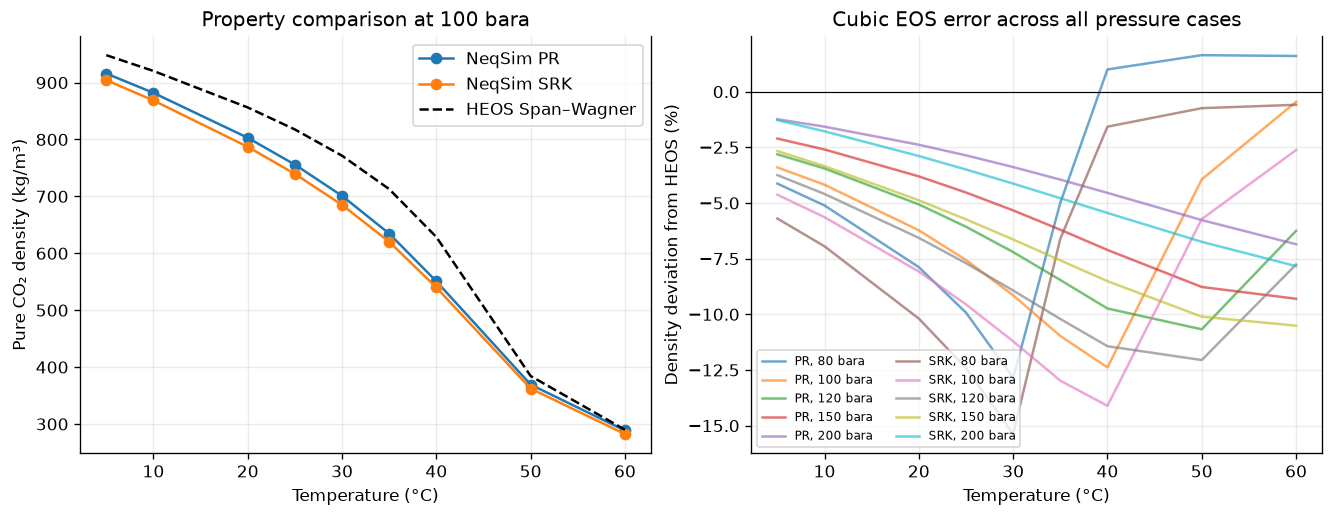

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), constrained_layout=True)
for eos, group in benchmark.loc[benchmark["pressure_bara"] == 100.0].groupby("EOS"):
    axes[0].plot(group["temperature_C"], group["density_kg_m3"], "o-", label=f"NeqSim {eos}")
reference_group = benchmark.query("EOS == 'PR' and pressure_bara == 100.0")
axes[0].plot(
    reference_group["temperature_C"], reference_group["HEOS_density_kg_m3"],
    "k--", label="HEOS Span–Wagner",
)
for eos, group in benchmark.groupby("EOS"):
    for pressure, points in group.groupby("pressure_bara"):
        axes[1].plot(
            points["temperature_C"], points["density_error_percent"],
            alpha=0.65, label=f"{eos}, {pressure:g} bara",
        )
axes[0].set_ylabel("Pure CO₂ density (kg/m³)")
axes[0].set_title("Property comparison at 100 bara")
axes[0].legend()
axes[1].set_ylabel("Density deviation from HEOS (%)")
axes[1].set_title("Cubic EOS error across all pressure cases")
axes[1].legend(ncol=2, fontsize=7)
axes[1].axhline(0.0, color="black", linewidth=0.7)
for axis in axes:
    axis.set_xlabel("Temperature (°C)")
    axis.grid(alpha=0.25)
fig.savefig(results_dir / "01_property_benchmark.png", dpi=160)
plt.show()

**Read the benchmark:** the largest errors can occur near steep density changes. A successful
flash does not establish reference-EOS accuracy. Use the printed errors to decide whether PR
is adequate for a particular duty; these are model discrepancies, not measured experimental
uncertainty. All 90 rows are exported at the end.

## 3. A composable injection well

The source stream and well are normal NeqSim objects in `ProcessSystem`, so the feed can later
come from a compressor, pump, cooler or transport model. Positive depth denotes downward
vertical distance; NeqSim elevation change is negative for injection. The specified flow and
wellhead pressure define a forward calculation; reservoir injectivity/backpressure is absent.

| Input | Value | Basis |
|---|---:|---|
| Vertical and measured length | 1,300 m | Straight vertical, synthetic |
| Tubing internal diameter | 0.1571 m | Synthetic |
| Absolute roughness | 0.000045 m | Synthetic |
| Wellhead pressure | 90 bara | Absolute pressure |
| Mass flow | 150,000 kg/h | 41.667 kg/s |
| Wellhead temperature | 10 / 25 °C | Sensitivity |
| Nitrogen | 0 / 1 mol% | Remaining component is CO₂ |
| Formation temperature | 4 °C at top, 43 °C at bottom | Linear with depth |
| Overall heat-transfer coefficient | 25 W/(m² K) | Assumed constant, tubing area basis |

Hydraulics use `PipeBeggsAndBrills`; thermodynamics use PR/classic. No empirical CO₂-specific
holdup/friction multiplier is applied by notebook code. We use a specified overall heat-transfer
coefficient rather than treating internal convection alone as the total formation resistance.

In [4]:
WELL_DEPTH_M = 1300.0
TUBING_ID_M = 0.1571
MASS_FLOW_KG_H = 150000.0
WELLHEAD_BARA = 90.0
FORMATION_TOP_C = 4.0
FORMATION_BOTTOM_C = 43.0
OVERALL_U_W_M2_K = 25.0


def run_well(inlet_temperature_c, nitrogen_fraction, segments=40, inner_h=False):
    tag = f"T{inlet_temperature_c:g}-N{100 * nitrogen_fraction:g}-n{segments}"
    feed = Stream(f"feed-{tag}", make_fluid(
        inlet_temperature_c, WELLHEAD_BARA, nitrogen_fraction
    ))
    feed.setFlowRate(MASS_FLOW_KG_H, "kg/hr")
    well = PipeBeggsAndBrills(f"injection-well-{tag}", feed)
    well.setLength(WELL_DEPTH_M)
    well.setElevation(-WELL_DEPTH_M)
    well.setDiameter(TUBING_ID_M)
    well.setPipeWallRoughness(4.5e-5)
    well.setNumberOfIncrements(segments)
    well.setFormationTemperatureGradient(
        FORMATION_TOP_C, -(FORMATION_BOTTOM_C - FORMATION_TOP_C) / WELL_DEPTH_M, "C"
    )
    if inner_h:
        well.setHeatTransferMode(PipeBeggsAndBrills.HeatTransferMode.ESTIMATED_INNER_H)
    else:
        well.setHeatTransferCoefficient(OVERALL_U_W_M2_K)
        well.setHeatTransferMode(PipeBeggsAndBrills.HeatTransferMode.SPECIFIED_U)
    process = ProcessSystem()
    process.add(feed)
    process.add(well)
    process.run()
    outlet = well.getOutletStream()
    relative_mass_error = abs(
        float(outlet.getFlowRate("kg/hr")) / float(feed.getFlowRate("kg/hr")) - 1.0
    )
    assert relative_mass_error < 1e-10
    depths = np.linspace(0.0, WELL_DEPTH_M, segments + 1)
    pressures = np.asarray(well.getPressureProfile(), dtype=float)
    temperatures = np.asarray(well.getTemperatureProfile(), dtype=float) - 273.15
    assert len(depths) == len(pressures) == len(temperatures)
    rows = []
    for depth, pressure, temperature in zip(depths, pressures, temperatures):
        state = flashed(temperature, pressure, nitrogen_fraction)
        density = float(state.getDensity("kg/m3"))
        rows.append({
            "case": tag,
            "inlet_temperature_C": inlet_temperature_c,
            "nitrogen_mol_percent": nitrogen_fraction * 100.0,
            "depth_m": depth,
            "pressure_bara": pressure,
            "fluid_temperature_C": temperature,
            "formation_temperature_C": FORMATION_TOP_C + (
                FORMATION_BOTTOM_C - FORMATION_TOP_C
            ) * depth / WELL_DEPTH_M,
            "density_kg_m3": density,
            "bulk_velocity_m_s": MASS_FLOW_KG_H / 3600.0 / density / (
                np.pi * TUBING_ID_M ** 2 / 4.0
            ),
            "phase_count": int(state.getNumberOfPhases()),
        })
    profile = pd.DataFrame(rows)
    assert np.isfinite(profile.select_dtypes(include="number").to_numpy()).all()
    assert (profile["pressure_bara"] > 0.0).all()
    assert (profile["density_kg_m3"] > 0.0).all()
    return process, feed, well, profile, relative_mass_error


well_cases = {
    (temperature, nitrogen): run_well(temperature, nitrogen)
    for temperature in (10.0, 25.0)
    for nitrogen in (0.0, 0.01)
}
steady_profiles = pd.concat([case[3] for case in well_cases.values()], ignore_index=True)
well_summary = steady_profiles.groupby("case", sort=False).tail(1).copy()
display(well_summary.drop(columns=["formation_temperature_C"]).round(4))
print("Maximum relative mass imbalance:", max(case[4] for case in well_cases.values()))
assert (well_summary["pressure_bara"] > WELLHEAD_BARA).all()

Maximum relative mass imbalance: 0.0


,case,inlet_temperature_C,nitrogen_mol_percent,depth_m,pressure_bara,fluid_temperature_C,density_kg_m3,bulk_velocity_m_s,phase_count
40,T10-N0-n40,10.0,0.0,1300.0,202.0914,16.9766,931.7949,2.3069,1
81,T10-N1-n40,10.0,1.0,1300.0,200.2531,17.2668,918.3039,2.3408,1
122,T25-N0-n40,25.0,0.0,1300.0,185.8572,33.7715,822.9614,2.6120,1
163,T25-N1-n40,25.0,1.0,1300.0,183.1717,34.3758,803.6206,2.6748,1


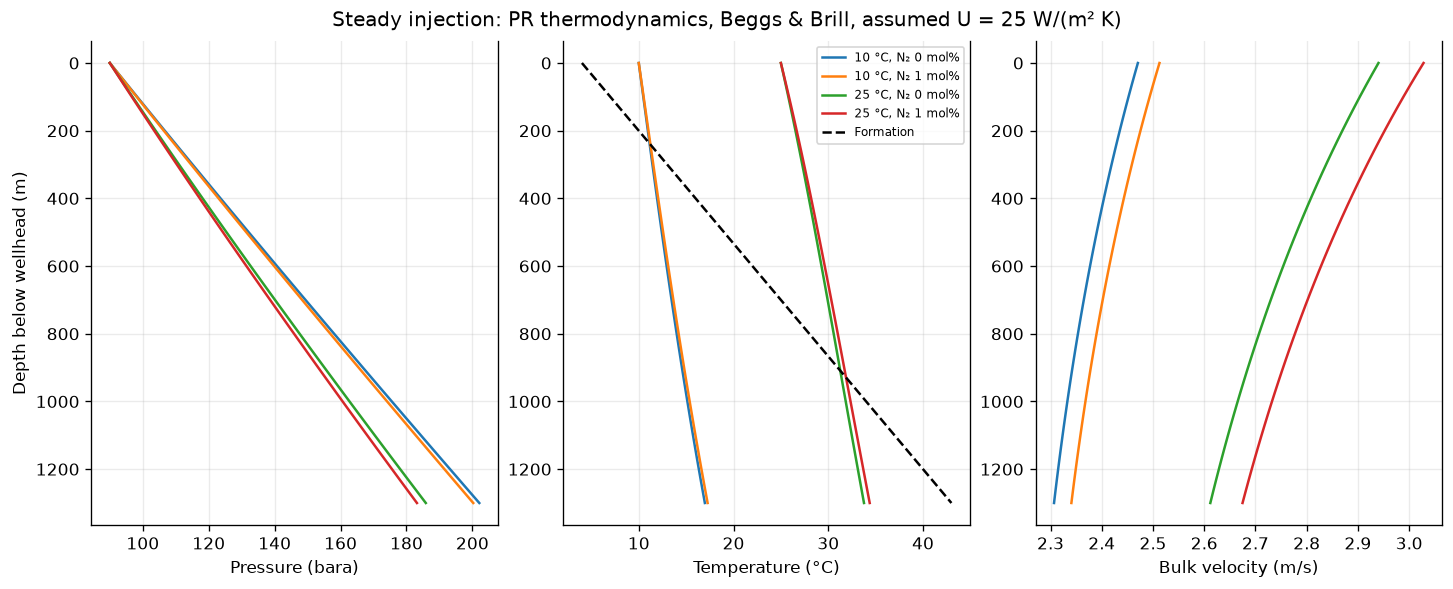

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4.8), constrained_layout=True)
for (temperature, nitrogen), case in well_cases.items():
    profile = case[3]
    label = f"{temperature:g} °C, N₂ {100 * nitrogen:g} mol%"
    for axis, column in zip(
        axes, ("pressure_bara", "fluid_temperature_C", "bulk_velocity_m_s")
    ):
        axis.plot(profile[column], profile["depth_m"], label=label)
formation = well_cases[(10.0, 0.0)][3]
axes[1].plot(
    formation["formation_temperature_C"], formation["depth_m"], "k--", label="Formation"
)
for axis, label in zip(axes, ("Pressure (bara)", "Temperature (°C)", "Bulk velocity (m/s)")):
    axis.set_xlabel(label)
    axis.invert_yaxis()
    axis.grid(alpha=0.25)
axes[0].set_ylabel("Depth below wellhead (m)")
axes[1].legend(fontsize=7, loc="best")
fig.suptitle("Steady injection: PR thermodynamics, Beggs & Brill, assumed U = 25 W/(m² K)")
fig.savefig(results_dir / "02_steady_profiles.png", dpi=160)
plt.show()

## 4. Numerical and API consistency checks

A 20/40/80-segment study reports the discretization sensitivity for the 10 °C, 1 mol% N₂
case. The acceptance limits between 40 and 80 segments are **1 bar and 1 K** at the outlet,
chosen for this teaching screen before execution. They do not qualify the underlying
correlation. We also cross-check the high-level analyzer against the direct pipe using its
own defaults: **20 increments and estimated internal h**. That cross-check intentionally
uses a different thermal model from the primary specified-U cases.

In [6]:
mesh_rows = []
for segments in (20, 40, 80):
    case = run_well(10.0, 0.01, segments=segments)
    outlet_row = case[3].iloc[-1]
    mesh_rows.append({
        "segments": segments,
        "BHP_bara": outlet_row["pressure_bara"],
        "BHT_C": outlet_row["fluid_temperature_C"],
    })
mesh_check = pd.DataFrame(mesh_rows).set_index("segments")
display(mesh_check.round(5))
mesh_change = (mesh_check.loc[80] - mesh_check.loc[40]).abs()
assert mesh_change["BHP_bara"] < 1.0
assert mesh_change["BHT_C"] < 1.0
print("Absolute 40→80 changes:", mesh_change.to_dict())

analyzer = CO2InjectionWellAnalyzer("synthetic-CO2-injector")
analyzer.setFluid(make_fluid(10.0, WELLHEAD_BARA, 0.01))
analyzer.setWellGeometry(WELL_DEPTH_M, TUBING_ID_M, 4.5e-5)
analyzer.setOperatingConditions(WELLHEAD_BARA, 10.0, MASS_FLOW_KG_H)
analyzer.setFormationTemperature(FORMATION_TOP_C, FORMATION_BOTTOM_C)
analyzer.addTrackedComponent("nitrogen", 0.05)
analyzer.runFullAnalysis()
design_case = analyzer.getResults().get("design_case")
direct_case = run_well(10.0, 0.01, segments=20, inner_h=True)[3].iloc[-1]
analyzer_comparison = pd.DataFrame({
    "quantity": ["BHP_bara", "BHT_C"],
    "analyzer": [float(design_case.get("BHP_bara")), float(design_case.get("BHT_C"))],
    "direct_pipe": [direct_case["pressure_bara"], direct_case["fluid_temperature_C"]],
})
analyzer_comparison["absolute_difference"] = (
    analyzer_comparison["analyzer"] - analyzer_comparison["direct_pipe"]
).abs()
assert analyzer_comparison["absolute_difference"].max() < 1e-5
display(analyzer_comparison.round(8))
print("Analyzer design-outlet phase/impurity screen:", bool(analyzer.isSafeToOperate()))
print("Registered N2 alarm:", design_case.get("alarm_results").get("nitrogen"))

Absolute 40→80 changes: {'BHP_bara': 0.07168886694850585, 'BHT_C': 0.04376870676588851}
Analyzer design-outlet phase/impurity screen: True
Registered N2 alarm: {threshold_mol_frac=0.05, gas_mol_frac=0.01, alarm_exceeded=false, status=within_limit}


,BHP_bara,BHT_C
segments,,
20,200.11062,17.35435
40,200.25307,17.26683
80,200.32476,17.22306


,quantity,analyzer,direct_pipe,absolute_difference
0,BHP_bara,191.931584,191.931584,0.0
1,BHT_C,43.245818,43.245818,0.0


`isSafeToOperate()` checks the design outlet's phase count and registered impurity alarms.
It is **not a well-integrity verdict** and does not certify tubing, cement, seals or shutdown.
Its alarm behaviour was repaired under [#3964](https://github.com/equinor/neqsim/issues/3964)
(closed); the current implementation is used above. The analyzer's built-in scans may skip
failed flashes, so the independently executed scan below fails immediately on any flash error.

## 5. Impurity partitioning during lower-pressure operation

At a fixed 10 °C, reduce pressure from 100 to 30 bara for a 99/1 mol% CO₂/N₂ mixture.
Each point is a separate equilibrium state, **not a depressurization trajectory**.
`ImpurityMonitor` reports gas mole fraction. A 5 mol% N₂ gas alarm is illustrative, not a
pipeline specification or toxicity limit. In a one-phase liquid there is no gas alarm reading;
that is represented by a gap rather than a zero concentration. The library gas label is
not a vapour-quality or supercritical-state test: a dense single phase can retain that tag.
Interpret gas/liquid partitioning where the phase count is two; do not call the reported
phase fraction a physical vapour quality outside that region.

Check component conservation using the equilibrium lever rule:
$$z_i=\sum_{k=1}^{N_p}\beta_k x_{i,k}$$
Here $z_i$ is bulk component mole fraction, $\beta_k$ is phase mole fraction, and $x_{i,k}$
is component mole fraction in phase $k$; $N_p$ is the number of fluid phases. All are dimensionless.

In [7]:
phase_rows = []
for pressure in np.linspace(30.0, 100.0, 71):
    state = flashed(10.0, float(pressure), 0.01)
    stream = Stream(f"partition-{pressure:g}", state)
    stream.setFlowRate(MASS_FLOW_KG_H, "kg/hr")
    stream.run()
    state = stream.getThermoSystem()
    monitor = ImpurityMonitor("N2-monitor", stream)
    monitor.addTrackedComponent("nitrogen", 0.05)
    component_residuals = []
    for component in ("CO2", "nitrogen"):
        reconstructed = sum(
            float(state.getPhase(k).getBeta())
            * float(state.getPhase(k).getComponent(component).getx())
            for k in range(int(state.getNumberOfPhases()))
        )
        component_residuals.append(abs(
            reconstructed - float(state.getComponent(component).getz())
        ))
    gas_exists = bool(state.hasPhaseType("gas"))
    phase_rows.append({
        "pressure_bara": pressure,
        "phase_count": int(state.getNumberOfPhases()),
        "gas_mole_fraction": float(monitor.getGasPhaseFraction()),
        "gas_N2_mol_percent": (
            100.0 * float(monitor.getGasPhaseMoleFraction("nitrogen"))
            if gas_exists else np.nan
        ),
        "gas_alarm_exceeded": bool(monitor.isAlarmExceeded("nitrogen")),
        "max_component_residual": max(component_residuals),
    })
phase_scan = pd.DataFrame(phase_rows)
assert phase_scan["max_component_residual"].max() < 1e-8
assert (phase_scan["phase_count"] > 1).any()
print("Maximum component mole-fraction residual:", phase_scan["max_component_residual"].max())
display(phase_scan.loc[
    (phase_scan["phase_count"] > 1) | phase_scan["gas_alarm_exceeded"]
].round(5))

Maximum component mole-fraction residual: 1.1275702593849246e-16


,pressure_bara,phase_count,gas_mole_fraction,gas_N2_mol_percent,gas_alarm_exceeded,max_component_residual
16,46.0,2,0.66734,1.38612,False,0.0
17,47.0,2,0.25153,2.65760,False,0.0
18,48.0,2,0.10532,3.87418,False,0.0
19,49.0,2,0.02850,5.03886,True,0.0


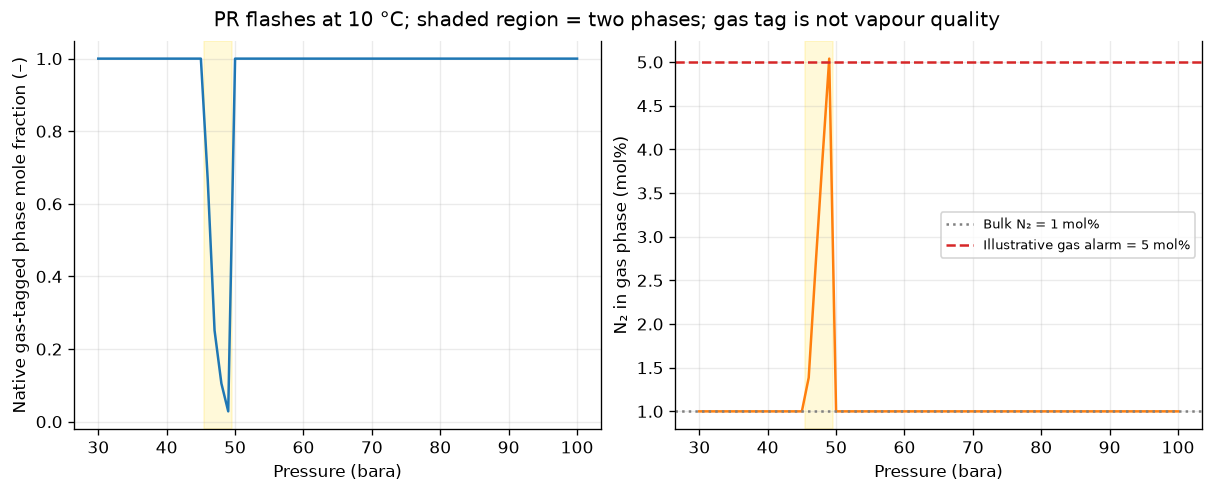

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
axes[0].plot(phase_scan["pressure_bara"], phase_scan["gas_mole_fraction"], color="tab:blue")
axes[0].set_ylabel("Native gas-tagged phase mole fraction (–)")
axes[1].plot(phase_scan["pressure_bara"], phase_scan["gas_N2_mol_percent"], color="tab:orange")
axes[1].axhline(1.0, color="grey", linestyle=":", label="Bulk N₂ = 1 mol%")
axes[1].axhline(5.0, color="tab:red", linestyle="--", label="Illustrative gas alarm = 5 mol%")
axes[1].set_ylabel("N₂ in gas phase (mol%)")
axes[1].legend(fontsize=8)
two_phase_pressures = phase_scan.loc[phase_scan["phase_count"] > 1, "pressure_bara"]
for axis in axes:
    axis.axvspan(
        two_phase_pressures.min() - 0.5, two_phase_pressures.max() + 0.5,
        color="gold", alpha=0.15,
    )
    axis.set_xlabel("Pressure (bara)")
    axis.grid(alpha=0.25)
fig.suptitle("PR flashes at 10 °C; shaded region = two phases; gas tag is not vapour quality")
fig.savefig(results_dir / "03_impurity_partitioning.png", dpi=160)
plt.show()

## 6. Native shutdown screen and its analytical check

`TransientWellbore` is a thermal-relaxation screen. It constructs a linear **assumed** initial
fluid temperature (inlet temperature at the top, inlet plus half the geothermal rise at the
bottom). It does not initialize from the preceding calculated flowing profile. Hydrostatic
pressure uses the initial inlet density throughout; it is not a sealed-inventory pressure
solution. We set the imposed depressurization rate to zero. The chosen 5 h time constant is
an input, not a fitted rock/cement heat-transfer solution. In this class setting radial h
does not determine that time constant.

At each fixed depth the implemented thermal response is checked against:
$$T(z,t)=T_f(z)+[T(z,0)-T_f(z)]\exp(-t/\tau)$$
$T$ is fluid temperature (K), $T_f$ formation temperature (K), $z$ depth (m), $t$ elapsed time
(h) and $\tau=5$ h. The native initial snapshot supplies $T(z,0)$. A 0.5 h rerun checks the
24 h endpoint. These are implementation and timestep checks, not validation of well shutdown
physics. The native snapshots retain their equilibrium phase counts.

In [9]:
def shutdown_screen(step_hours):
    feed = well_cases[(10.0, 0.01)][1]
    transient = TransientWellbore("shutdown-screen", feed)
    transient.setWellDepth(WELL_DEPTH_M)
    transient.setTubingDiameter(TUBING_ID_M)
    transient.setNumberOfSegments(20)
    transient.setFormationTemperature(FORMATION_TOP_C + 273.15, FORMATION_BOTTOM_C + 273.15)
    transient.setShutdownCoolingRate(5.0)
    transient.setDepressurizationRate(0.0)
    transient.runShutdownSimulation(24.0, step_hours)
    snapshots = list(transient.getSnapshots())
    initial = np.asarray(snapshots[0].temperatures, dtype=float)
    depths = np.asarray(snapshots[0].depths, dtype=float)
    formation_k = FORMATION_TOP_C + 273.15 + (
        FORMATION_BOTTOM_C - FORMATION_TOP_C
    ) * depths / WELL_DEPTH_M
    rows = []
    maximum_thermal_error = 0.0
    for snapshot in snapshots:
        time_hours = float(snapshot.timeHours)
        temperatures_k = np.asarray(snapshot.temperatures, dtype=float)
        expected = formation_k + (initial - formation_k) * np.exp(-time_hours / 5.0)
        maximum_thermal_error = max(
            maximum_thermal_error, float(np.max(np.abs(temperatures_k - expected)))
        )
        for index, depth in enumerate(depths):
            rows.append({
                "time_h": time_hours,
                "depth_m": depth,
                "fluid_temperature_C": temperatures_k[index] - 273.15,
                "pressure_bara": float(snapshot.pressures[index]),
                "phase_count": int(snapshot.numberOfPhases[index]),
                "gas_mole_fraction": float(snapshot.gasFraction[index]),
            })
    assert maximum_thermal_error < 1e-9
    return transient, pd.DataFrame(rows), maximum_thermal_error


shutdown_model, shutdown_results, shutdown_analytical_error = shutdown_screen(1.0)
refined_shutdown = shutdown_screen(0.5)[1]
final_temperature = shutdown_results.query("time_h == 24.0")["fluid_temperature_C"].to_numpy()
refined_temperature = refined_shutdown.query("time_h == 24.0")["fluid_temperature_C"].to_numpy()
shutdown_step_error = float(np.max(np.abs(final_temperature - refined_temperature)))
assert shutdown_step_error < 1e-9
initial_native = shutdown_results.query("time_h == 0.0")
flowing_case = well_cases[(10.0, 0.01)][3]
initialization_difference = float(initial_native.iloc[-1]["fluid_temperature_C"]) - float(
    flowing_case.iloc[-1]["fluid_temperature_C"]
)
print("Maximum analytical thermal error (K):", shutdown_analytical_error)
print("24 h endpoint change, 1→0.5 h (K):", shutdown_step_error)
print("Native assumed initial BHT minus calculated flowing BHT (K):", initialization_difference)
display(shutdown_results.loc[
    shutdown_results["time_h"].isin([0.0, 5.0, 24.0])
    & shutdown_results["depth_m"].isin([0.0, WELL_DEPTH_M / 2.0, WELL_DEPTH_M])
].round(4))

Maximum analytical thermal error (K): 5.684341886080802e-14
24 h endpoint change, 1→0.5 h (K): 1.1368683772161603e-13
Native assumed initial BHT minus calculated flowing BHT (K): 12.233166566371665


,time_h,depth_m,fluid_temperature_C,pressure_bara,phase_count,gas_mole_fraction
0,0.0,0.0,10.0000,90.0000,1,1.0
10,0.0,650.0,19.7500,144.5489,1,1.0
20,0.0,1300.0,29.5000,199.0977,1,1.0
105,5.0,0.0,6.2073,90.0000,1,1.0
115,5.0,650.0,22.1205,144.5489,1,1.0
125,5.0,1300.0,38.0336,199.0977,1,1.0
504,24.0,0.0,4.0494,90.0000,1,1.0
514,24.0,650.0,23.4691,144.5489,1,1.0
524,24.0,1300.0,42.8889,199.0977,1,1.0


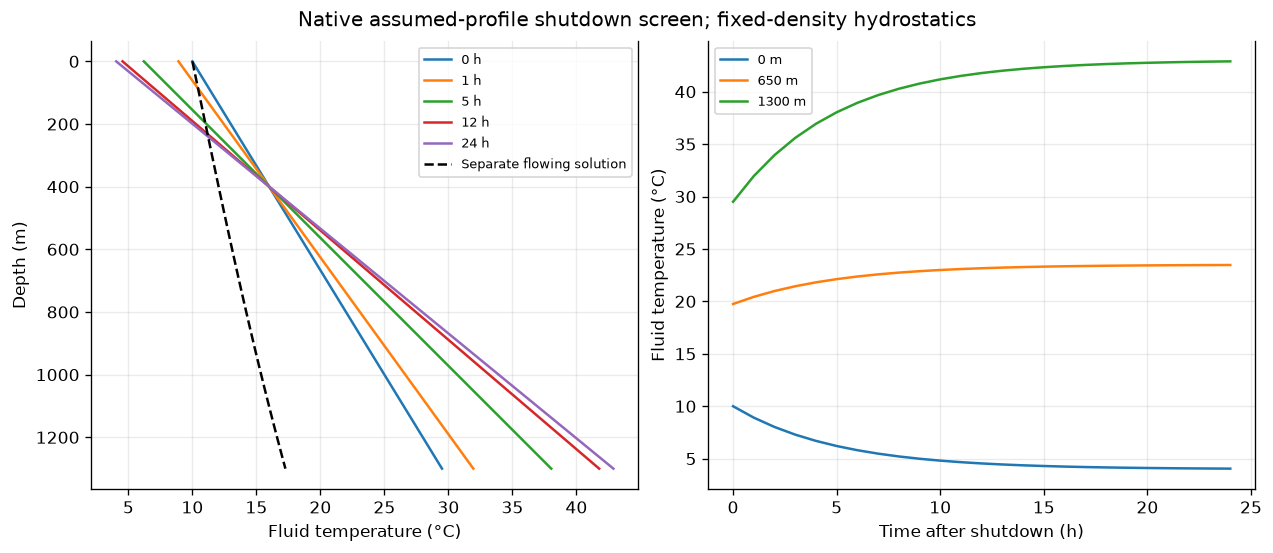

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), constrained_layout=True)
for time_hours in (0.0, 1.0, 5.0, 12.0, 24.0):
    profile = shutdown_results.query("time_h == @time_hours")
    axes[0].plot(profile["fluid_temperature_C"], profile["depth_m"], label=f"{time_hours:g} h")
axes[0].plot(
    flowing_case["fluid_temperature_C"], flowing_case["depth_m"],
    "k--", label="Separate flowing solution",
)
axes[0].invert_yaxis()
axes[0].set_xlabel("Fluid temperature (°C)")
axes[0].set_ylabel("Depth (m)")
axes[0].legend(fontsize=8)
for depth in (0.0, WELL_DEPTH_M / 2.0, WELL_DEPTH_M):
    history = shutdown_results.query("depth_m == @depth")
    axes[1].plot(history["time_h"], history["fluid_temperature_C"], label=f"{depth:g} m")
axes[1].set_xlabel("Time after shutdown (h)")
axes[1].set_ylabel("Fluid temperature (°C)")
axes[1].legend(fontsize=8)
for axis in axes:
    axis.grid(alpha=0.25)
fig.suptitle("Native assumed-profile shutdown screen; fixed-density hydrostatics")
fig.savefig(results_dir / "04_shutdown_screen.png", dpi=160)
plt.show()

## 7. From fluid temperature to an explicit thermal-load bound

A separate Python elastic calculation illustrates **only the incremental axial thermal
stress**. Assume the tubing wall instantly reaches the local calculated fluid temperature;
take the pre-injection stress-free wall temperature as the formation temperature. Cooling
under axial restraint produces positive tensile stress:
$$\Delta\sigma_{\mathrm{ax,th}}=-R E\alpha(T_{\mathrm{wall}}-T_{\mathrm{ref}})$$
$E=200$ GPa is assumed Young's modulus, $\alpha=12\times10^{-6}$ K⁻¹ thermal expansion,
$R$ a dimensionless restraint fraction (0–1), and temperature differences are in K.
Stress is reported in MPa. This is a free-expansion ($R=0$) to fully restrained ($R=1$)
loading sensitivity for uniform wall temperature, not a tubing failure criterion.

Actual wall temperature and restraint require radial heat transfer and completion mechanics.
Pressure stress, axial weight, piston/ballooning effects, buckling, packer loads, defects,
cement debonding, fatigue and temperature-dependent strength/toughness are absent.
The fluid-to-wall assumption can overstate or understate local stresses; it is not a universal
conservative design bound. We therefore report no safety factor or certified operating envelope.

Analytical check: 40 K cooling, full restraint → 96 MPa tensile increment


,peak_tensile_increment_MPa,peak_compressive_increment_MPa
case,,
T10-N0-n40,62.456,-14.4
T10-N1-n40,61.760,-14.4
T25-N0-n40,22.148,-50.4
T25-N1-n40,20.698,-50.4


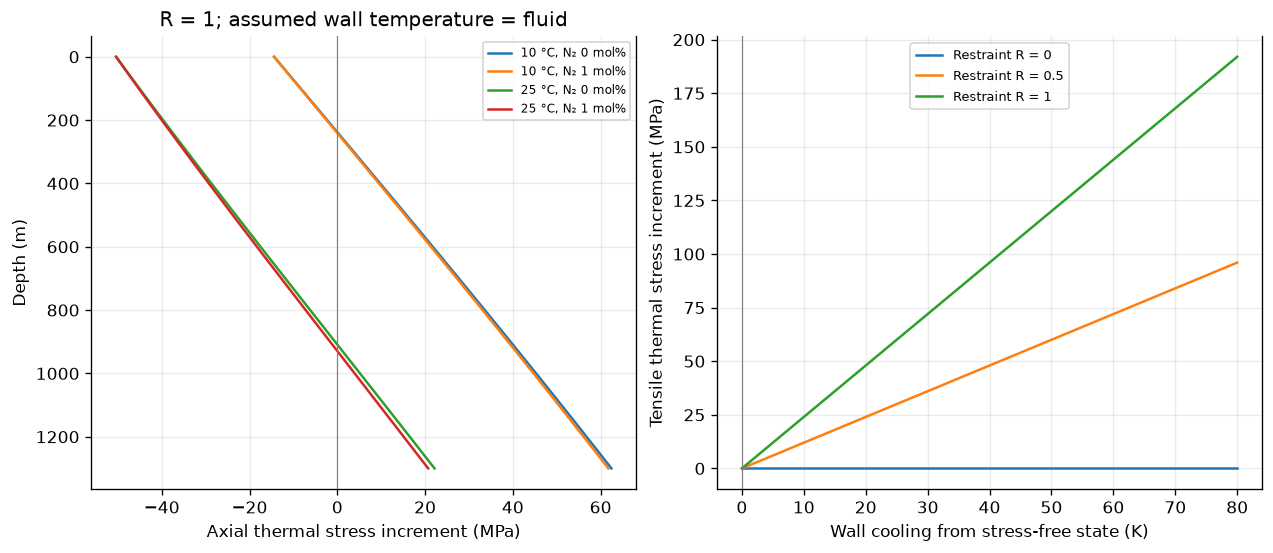

In [11]:
YOUNGS_MODULUS_PA = 200e9
THERMAL_EXPANSION_PER_K = 12e-6
thermal_loads = steady_profiles.copy()
thermal_loads["wall_temperature_proxy_C"] = thermal_loads["fluid_temperature_C"]
thermal_loads["fully_restrained_increment_MPa"] = (
    -YOUNGS_MODULUS_PA * THERMAL_EXPANSION_PER_K
    * (thermal_loads["wall_temperature_proxy_C"] - thermal_loads["formation_temperature_C"])
    / 1e6
)
assert np.isclose(YOUNGS_MODULUS_PA * THERMAL_EXPANSION_PER_K * 40.0 / 1e6, 96.0)
assert np.isclose(0.0 * thermal_loads["fully_restrained_increment_MPa"].max(), 0.0)
thermal_summary = thermal_loads.groupby("case").agg(
    peak_tensile_increment_MPa=("fully_restrained_increment_MPa", "max"),
    peak_compressive_increment_MPa=("fully_restrained_increment_MPa", "min"),
)
display(thermal_summary.round(3))
print("Analytical check: 40 K cooling, full restraint → 96 MPa tensile increment")

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.5), constrained_layout=True)
for (temperature, nitrogen), case in well_cases.items():
    case_name = case[3].iloc[0]["case"]
    profile = thermal_loads.loc[thermal_loads["case"] == case_name]
    axes[0].plot(
        profile["fully_restrained_increment_MPa"], profile["depth_m"],
        label=f"{temperature:g} °C, N₂ {100 * nitrogen:g} mol%",
    )
axes[0].invert_yaxis()
axes[0].set_xlabel("Axial thermal stress increment (MPa)")
axes[0].set_ylabel("Depth (m)")
axes[0].legend(fontsize=7)
axes[0].set_title("R = 1; assumed wall temperature = fluid")
cooling_k = np.linspace(0.0, 80.0, 81)
for restraint in (0.0, 0.5, 1.0):
    stress_mpa = restraint * YOUNGS_MODULUS_PA * THERMAL_EXPANSION_PER_K * cooling_k / 1e6
    axes[1].plot(cooling_k, stress_mpa, label=f"Restraint R = {restraint:g}")
axes[1].set_xlabel("Wall cooling from stress-free state (K)")
axes[1].set_ylabel("Tensile thermal stress increment (MPa)")
axes[1].legend(fontsize=8)
for axis in axes:
    axis.axvline(0.0, color="grey", linewidth=0.7)
    axis.grid(alpha=0.25)
fig.savefig(results_dir / "05_thermal_loading.png", dpi=160)
plt.show()

## 8. Results, validation and reusable handoff

The final cell prints the results that should be carried into an engineering discussion.
CSV files and a JSON provenance record make the boundary data reusable, while the preceding
inline tables and plots remain the primary record. The ZIP contains the **complete** property,
steady, phase-scan, shutdown, thermal-load and numerical-check tables plus every saved figure.

Validation achieved: an independent pure-CO₂ property reference; equilibrium component and
steady total-mass checks; a spatial-refinement check; analyzer/direct-pipe agreement; exact
thermal-relaxation and elastic analytical checks. It does not include an experimental well
benchmark, coupled reservoir injection or a mechanical-integrity validation.

In [12]:
tables = {
    "property_benchmark": benchmark,
    "property_summary": benchmark_summary,
    "steady_profiles": steady_profiles,
    "well_summary": well_summary,
    "mesh_check": mesh_check,
    "analyzer_comparison": analyzer_comparison,
    "phase_scan": phase_scan,
    "shutdown_screen": shutdown_results,
    "thermal_loads": thermal_loads,
    "thermal_summary": thermal_summary,
}
for name, table in tables.items():
    table.to_csv(results_dir / f"{name}.csv", index=name in {
        "property_summary", "mesh_check", "thermal_summary"
    })
validation = {
    "relative_mass_error_max": max(case[4] for case in well_cases.values()),
    "component_mole_fraction_residual_max": float(phase_scan["max_component_residual"].max()),
    "mesh_40_to_80_abs_changes": mesh_change.to_dict(),
    "analyzer_direct_abs_difference_max": float(analyzer_comparison["absolute_difference"].max()),
    "shutdown_analytical_error_K": shutdown_analytical_error,
    "shutdown_timestep_endpoint_error_K": shutdown_step_error,
    "shutdown_assumed_minus_flowing_initial_BHT_K": initialization_difference,
    "paper_numerical_reproduction": False,
    "integrity_qualification": False,
}
(results_dir / "provenance_and_validation.json").write_text(
    json.dumps({"provenance": provenance, "validation": validation}, indent=2),
    encoding="utf-8",
)
archive_path = Path("co2_well_integrity_results.zip")
with zipfile.ZipFile(archive_path, "w", zipfile.ZIP_DEFLATED) as archive:
    for output_path in sorted(results_dir.iterdir()):
        archive.write(output_path, arcname=output_path.name)

max_density_error = benchmark.groupby("EOS")["density_error_percent"].apply(
    lambda values: values.abs().max()
)
display(Markdown(
    f"**Computed findings:** PR maximum density deviation is {max_density_error['PR']:.2f}% "
    f"and SRK {max_density_error['SRK']:.2f}% over the selected grid. "
    f"The four specified-U well cases give BHP {well_summary['pressure_bara'].min():.2f}–"
    f"{well_summary['pressure_bara'].max():.2f} bara and BHT "
    f"{well_summary['fluid_temperature_C'].min():.2f}–"
    f"{well_summary['fluid_temperature_C'].max():.2f} °C. "
    f"Peak N₂ in an existing gas phase is {phase_scan['gas_N2_mol_percent'].max():.2f} mol%. "
    f"The native assumed shutdown initial BHT differs from the flowing solution by "
    f"{initialization_difference:.2f} K, demonstrating why these models cannot be joined "
    "without an explicit initialization contract."
))
print(json.dumps(validation, indent=2))
print("Reusable archive:", str(archive_path.resolve()))
print("Archive files:", sorted(path.name for path in results_dir.iterdir()))

{
  "relative_mass_error_max": 0.0,
  "component_mole_fraction_residual_max": 1.1275702593849246e-16,
  "mesh_40_to_80_abs_changes": {
    "BHP_bara": 0.07168886694850585,
    "BHT_C": 0.04376870676588851
  },
  "analyzer_direct_abs_difference_max": 0.0,
  "shutdown_analytical_error_K": 5.684341886080802e-14,
  "shutdown_timestep_endpoint_error_K": 1.1368683772161603e-13,
  "shutdown_assumed_minus_flowing_initial_BHT_K": 12.233166566371665,
  "paper_numerical_reproduction": false,
  "integrity_qualification": false
}
Reusable archive: /workspace/scratch/8dfd0ed20357/colab/co2_well_integrity_results.zip
Archive files: ['01_property_benchmark.png', '02_steady_profiles.png', '03_impurity_partitioning.png', '04_shutdown_screen.png', '05_thermal_loading.png', 'analyzer_comparison.csv', 'mesh_check.csv', 'phase_scan.csv', 'property_benchmark.csv', 'property_summary.csv', 'provenance_and_validation.json', 'shutdown_screen.csv', 'steady_profiles.csv', 'thermal_loads.csv', 'thermal_summary.csv'

**Computed findings:** PR maximum density deviation is 12.86% and SRK 15.38% over the selected grid. The four specified-U well cases give BHP 183.17–202.09 bara and BHT 16.98–34.38 °C. Peak N₂ in an existing gas phase is 5.04 mol%. The native assumed shutdown initial BHT differs from the flowing solution by 12.23 K, demonstrating why these models cannot be joined without an explicit initialization contract.

## 9. Research gaps and next exercises

The notebook advances the executable workflow requested by [#4509](https://github.com/equinor/neqsim/issues/4509);
it leaves the broader paper-validation question open. Existing campaigns
[#2911](https://github.com/equinor/neqsim/issues/2911) and
[#4228](https://github.com/equinor/neqsim/issues/4228) track conservative dynamics,
steady-to-transient initialization and well/injection-network qualification. The native
shutdown limitations identified above belong to those open capabilities; no claim of
full transient or well-integrity fidelity is made. No additional untracked library defect
was established by the successful cases in this notebook.

1. Change wellhead temperature, rate or assumed U and rerun every cell. Compare BHP/BHT,
   phase counts and thermal loading rather than selecting a case solely on one metric.
2. Obtain the full SPE paper and its geometry, thermal properties, inlet and reservoir
   boundary conditions, software/version, measured or tabulated profiles and uncertainty.
   Add a matched-case error table before claiming a paper benchmark.
3. Couple a conservative distributed well model initialized from a saved steady profile,
   retaining mass/energy inventories, wall/formation thermal storage and backpressure.
4. Transfer fluid boundaries to a qualified tubular/cement mechanics solver with actual
   completion constraints. Separately qualify cold-material toughness and dry-ice risks.

**Limits:** fluid-only PR flashes do not model solid CO₂ in this notebook. None of the sampled
states approaches the pure-CO₂ triple-point temperature (216.592 K). That observation is not
a solid-formation exclusion for arbitrary mixture depressurization paths. Hydrates, aqueous
corrosion, cement chemistry, leakage, cyclic fatigue and well barriers are outside scope.
The earlier [cold-injection/interface notebook](co2_injection_interface_paper_3959.ipynb)
provides a complementary fluid-to-THM handoff for a different paper.

**References and source audit**

- Kang, Liu and Fleica (2025), [SPE-229116-MS](https://doi.org/10.2118/229116-MS).
  Bibliographic target supplied by #4509; no full-paper numerical values used.
- Span and Wagner (1996), [DOI 10.1063/1.555991](https://doi.org/10.1063/1.555991),
  as implemented by [CoolProp](https://coolprop.org/fluid_properties/fluids/CarbonDioxide.html).
- [Pinned NeqSim well-analysis documentation](https://github.com/equinor/neqsim/blob/cb94f1d10cbc12f5aa6452c095fe58c8ff44f3ae/docs/process/co2_injection_well_analysis.md)
  and [TransientWellbore source](https://github.com/equinor/neqsim/blob/cb94f1d10cbc12f5aa6452c095fe58c8ff44f3ae/src/main/java/neqsim/process/equipment/pipeline/TransientWellbore.java).
- The thermal stress relation is derived from zero total axial strain:
  $\epsilon_{\mathrm{tot}}=\sigma/E+\alpha\Delta T=0$ for complete restraint,
  with $R$ introduced only as a declared sensitivity factor.